In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import tensorflow_datasets as tfds

In [2]:
# Upgrade tensorflow_datasets and protobuf to resolve potential version conflicts
!pip install --upgrade tensorflow-datasets protobuf

print("Upgraded tensorflow-datasets and protobuf. Please re-run the import cell and the dataset loading cell above (7b1c7b02 and 2188be71).")

Upgraded tensorflow-datasets and protobuf. Please re-run the import cell and the dataset loading cell above (7b1c7b02 and 2188be71).


### 1. Load and Preprocess the Dataset

We'll use `tf.keras.utils.image_dataset_from_directory` to load images. Make sure your dataset is structured like this:

```
dataset_root/
  train/
    cats/
      cat1.jpg
      cat2.jpg
    dogs/
      dog1.jpg
      dog2.jpg
  validation/
    cats/
      cat3.jpg
      cat4.jpg
    dogs/
      dog3.jpg
      dog4.jpg
```

**Note**: Replace `'/content/drive/MyDrive/cats_vs_dogs'` with the actual path to your dataset. If you don't have the dataset, you'll need to download it (e.g., from Kaggle).

In [3]:
# Define image parameters
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32

# Install missing dependency if needed
!pip install importlib_resources

# Load the cats_vs_dogs dataset using tensorflow_datasets
# Note: The 'cats_vs_dogs' dataset has a 'train' split which we'll divide into training and validation.
(ds_train, ds_val), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'], # 80% for training, 20% for validation
    shuffle_files=True,
    as_supervised=True, # Returns (image, label) tuples
    with_info=True,
)

# Preprocessing function
def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_HEIGHT, IMG_WIDTH))
    image = tf.cast(image, tf.float32) / 255.0 # Normalize to [0, 1]
    return image, tf.cast(label, tf.float32) # Ensure label is float for binary crossentropy

# Apply preprocessing and batching
train_ds = ds_train.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.cache().shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = ds_val.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dataset loaded and preprocessed using tensorflow_datasets.")
# print example counts if available, ds_info can provide detailed split information
if 'train' in ds_info.splits:
    total_examples = ds_info.splits['train'].num_examples
    print(f"Number of training examples: {int(total_examples * 0.8)}")
    print(f"Number of validation examples: {int(total_examples * 0.2)}")
else:
    print("Could not retrieve detailed split information for example counts.")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.IX0Y7F_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded and preprocessed using tensorflow_datasets.
Number of training examples: 18609
Number of validation examples: 4652


### 2. Build the Convolutional Neural Network (CNN)

We'll create a simple CNN model. The key here is the output layer: a `Dense` layer with 1 unit and a `sigmoid` activation function for binary classification.

In [4]:
model = keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),layers.MaxPooling2D((2, 2)),layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid') # Sigmoid output for binary classification
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3. Compile the Model

For binary classification with a sigmoid output, we use `binary_crossentropy` as the loss function.

In [5]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
print("Model compiled.")

Model compiled.


### 4. Train the Model

Now, let's train the network using the prepared training and validation datasets.

In [6]:
EPOCHS = 1

history = model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS)

print("Model training complete.")

582/582 ━━━━━━━━━━━━━━━━━━━━ 46s 62ms/step - accuracy: 0.6245 - loss: 0.6417 - val_accuracy: 0.7100 - val_loss: 0.5477
Model training complete.


### 5. Visualize Training History (Optional)

You can visualize the training accuracy and loss over epochs to understand how your model performed.

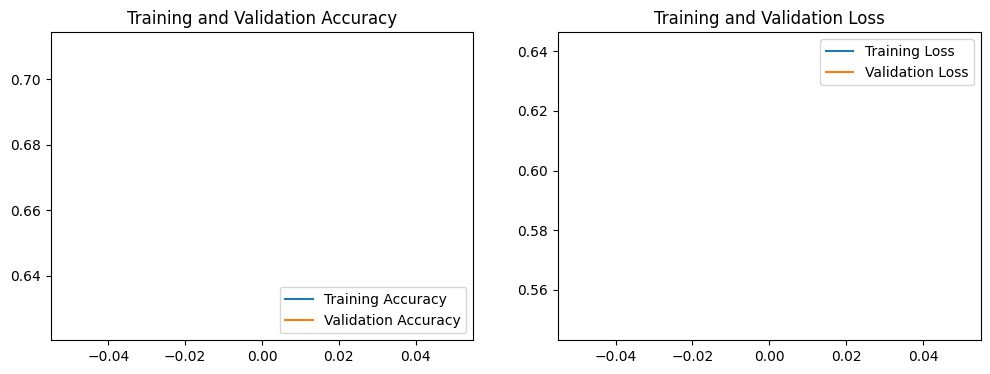

In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()